In [32]:
from langgraph.graph import StateGraph , START , END, add_messages
from typing import TypedDict, Literal, Annotated 
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.checkpoint.memory import MemorySaver

In [33]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages] #add_messages used to append messages within the basemessage list
    

In [34]:
llm = ChatGoogleGenerativeAI(model="gemini-3.1-flash-lite")
def chat_node(state: ChatState):
    #take user query from state 
    messages = state["messages"]
    #send to llm
    response = llm.invoke(messages)
    #store response in state 
    return {'messages': [response]}

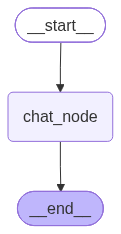

In [35]:
checkpointer = MemorySaver()
graph = StateGraph(ChatState)

#adding nodes 
# Register the 'chat_node' function as a node in the graph
graph.add_node('chat_node', chat_node)

#adding edges
graph.add_edge(START, 'chat_node')
graph.add_edge('chat_node', END)

graph.compile(checkpointer=checkpointer)

In [40]:
chatbot = graph.compile(checkpointer=checkpointer)

In [41]:
initial_state={
    'messages': [HumanMessage(content="What is the capital of India?")]

}

response = chatbot.invoke(initial_state)
response_text = response['messages'][-1].content
print(response_text)

ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

In [43]:
thread_id = '1'
while True:

    user_message = input('Type here: ')

    print('User: ', user_message)

    if user_message.strip().lower() in ['exit', 'bye', 'quit']:
        break

    config = {'configurable': {'thread_id': thread_id}}

    # Send the user's latest message to the chatbot graph.
    # The graph expects a state dictionary with a "messages" list,
    # so we wrap the raw text in a HumanMessage before invoking the model.
    response = chatbot.invoke({'messages': [HumanMessage(content=user_message)]}, config=config)

    print('AI :', response['messages'][-1].content)

User:  Hi my name is Sreyashee Roy
AI : [{'type': 'text', 'text': 'Hello Sreyashee Roy! It’s a pleasure to meet you. How are you doing today? Is there anything I can help you with?', 'extras': {'signature': 'EnIKcAFpFH0TdJnUsiXRgDdxIXWH8RWPr+yxYS6xZs1bUPGoVnnMqqFzwrcoT63FtSNsjt/HKO9KUgCgpVlNaEvwqo5ldFOTJl2msL5uszqbAKWlD2j3Csa6iZpbQ8/Nv/2MUlQMdpWQzjkLKyeTMeoCVWc='}}]
User:  What is my name ?
AI : [{'type': 'text', 'text': 'Your name is Sreyashee Roy.', 'extras': {'signature': 'EnIKcAFpFH0TjPyjkHmmJhbS4NXxGmn5vy4XA8Yb8CiRJwM5An2kUMzPFOV8zukG8owDijqKk407/kfS+ayCvC5FXMyCRvO5WBTZTvB+Cctg3ZyPwPytOK8uWMLon2zFDVT/b+eOHtcsjosTbbB0hQ6kdbU='}}]
User:  Ok very good. I have a pet whose name is Muffin . Its a Beagle dog. 
AI : [{'type': 'text', 'text': 'That is adorable! Beagles are such wonderful, friendly dogs—they are well-known for being curious and having a great sense of smell. "Muffin" is a really cute name for a Beagle!\n\nHow old is Muffin? I’d love to hear more about him (or her)—does Muff

In [44]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='Hi my name is Sreyashee Roy', additional_kwargs={}, response_metadata={}, id='5d01f435-0d73-46be-a8ea-f29e5edf75ab'), AIMessage(content=[{'type': 'text', 'text': 'Hello Sreyashee Roy! It’s a pleasure to meet you. How are you doing today? Is there anything I can help you with?', 'extras': {'signature': 'EnIKcAFpFH0TdJnUsiXRgDdxIXWH8RWPr+yxYS6xZs1bUPGoVnnMqqFzwrcoT63FtSNsjt/HKO9KUgCgpVlNaEvwqo5ldFOTJl2msL5uszqbAKWlD2j3Csa6iZpbQ8/Nv/2MUlQMdpWQzjkLKyeTMeoCVWc='}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.1-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a12734-c0c1-7000-8fee-07c6bf74815a-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 31, 'total_tokens': 41, 'input_token_details': {'cache_read': 0}}), HumanMessage(content='What is my name ?', additional_kwargs={}, response_metadata={}, id='a168b019-bc65